# 1. Please parse this csv, get the insight of the data customer-100000.csv

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("customers-100000.csv")

In [3]:
print(df.head())

   Index      Customer Id First Name   Last Name                    Company  \
0      1  ffeCAb7AbcB0f07      Jared      Jarvis           Sanchez-Fletcher   
1      2  b687FfC4F1600eC      Marie      Malone                  Mckay PLC   
2      3  9FF9ACbc69dcF9c     Elijah     Barrera             Marks and Sons   
3      4  b49edDB1295FF6E     Sheryl  Montgomery  Kirby, Vaughn and Sanders   
4      5  3dcCbFEB17CCf2E     Jeremy     Houston             Lester-Manning   

             City                                       Country  \
0   Hatfieldshire                                       Eritrea   
1  Robertsonburgh                                      Botswana   
2         Kimbury                                      Barbados   
3     Briannaview  Antarctica (the territory South of 60 deg S)   
4   South Brianna                                    Micronesia   

                Phone 1               Phone 2  \
0    274.188.8773x41185  001-215-760-4642x969   
1          283-236-9529 

In [4]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 12 columns):
 #   Column             Non-Null Count   Dtype 
---  ------             --------------   ----- 
 0   Index              100000 non-null  int64 
 1   Customer Id        100000 non-null  object
 2   First Name         100000 non-null  object
 3   Last Name          100000 non-null  object
 4   Company            100000 non-null  object
 5   City               100000 non-null  object
 6   Country            100000 non-null  object
 7   Phone 1            100000 non-null  object
 8   Phone 2            100000 non-null  object
 9   Email              100000 non-null  object
 10  Subscription Date  100000 non-null  object
 11  Website            100000 non-null  object
dtypes: int64(1), object(11)
memory usage: 9.2+ MB
None


In [5]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [6]:
print(df.describe(include="all"))

                Index      Customer Id First Name Last Name       Company  \
count   100000.000000           100000     100000    100000        100000   
unique            NaN           100000        690      1000         71994   
top               NaN  53DBF8C8e33007b       Joan  Campbell  Campbell Ltd   
freq              NaN                1        183       139            17   
mean     50000.500000              NaN        NaN       NaN           NaN   
std      28867.657797              NaN        NaN       NaN           NaN   
min          1.000000              NaN        NaN       NaN           NaN   
25%      25000.750000              NaN        NaN       NaN           NaN   
50%      50000.500000              NaN        NaN       NaN           NaN   
75%      75000.250000              NaN        NaN       NaN           NaN   
max     100000.000000              NaN        NaN       NaN           NaN   

                  City Country            Phone 1                Phone 2  \

In [7]:
dupes = df[df["Email"].duplicated(keep=False)].sort_values("Email")
print(len(dupes))
dupes[["Customer Id", "First Name", "Last Name", "Company", "Email", "Subscription Date"]]

10


,Customer Id,First Name,Last Name,Company,Email,Subscription Date
85112,5BcEBD82eBFf102,Charles,Freeman,"Barry, Gaines and Carroll",imitchell@church.com,2021-02-21
93818,DDdA80d1beD99b6,Joshua,Gallegos,Richards LLC,imitchell@church.com,2020-10-08
90751,8A2E9e5af981CBd,Alvin,Stephens,Bolton-Torres,julia03@briggs.com,2022-05-16
96681,64ff4a97cCF99Da,Kathy,Rojas,Burke-Schroeder,julia03@briggs.com,2020-04-17
18196,EdAD6f6E81F68Fc,Alison,Archer,Scott-Buchanan,kwalls@white.com,2020-08-02
95616,d44BCA84DEAf5EB,Lindsey,Carson,Boyd-Mcneil,kwalls@white.com,2020-04-13
31997,B29Fb3EF18604f8,Jaclyn,Torres,"Valencia, Newton and Carroll",ushields@saunders.com,2020-10-30
73003,C2DB1665c793Df8,Cristina,Cox,"Meyer, Davenport and Bailey",ushields@saunders.com,2021-04-29
30556,b0E5A8E4E2beF72,Tammy,Ramirez,Horne PLC,vgeorge@mendoza.com,2022-04-17
71528,b6Bcf35CE3e63b6,Kenneth,Mcpherson,Fuentes-Conrad,vgeorge@mendoza.com,2021-12-19


# Insights
1. There is no repeated order / resubscription data, based on top frequency of customer_id = 1, so we can assume this csv only contains a new user subscription. 
2. Some of the customer uses the same email, but the email does not match any of their first name nor last name. This suggest the data have quality issue or the dataset is synthetic.

Checking the distribution of the monthly subscription

In [8]:
df["Subscription Date"] = pd.to_datetime(
    df["Subscription Date"],
    errors="coerce"
)

df["year"] = df["Subscription Date"].dt.year
df["month"] = df["Subscription Date"].dt.month

In [9]:
monthly_counts = (
    df.groupby(["year", "month"])
      .size()
      .reset_index(name="count")
)

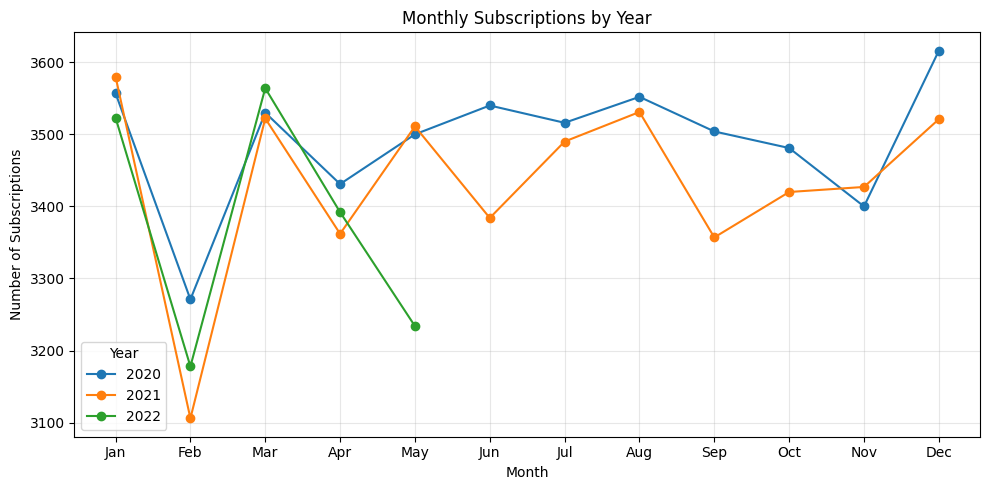

In [10]:
monthly_pivot = monthly_counts.pivot(
    index="month",
    columns="year",
    values="count"
).reindex(range(1, 13), fill_value=0)

monthly_pivot.plot(
    kind="line",
    marker="o",
    figsize=(10, 5)
)

plt.title("Monthly Subscriptions by Year")
plt.xlabel("Month")
plt.ylabel("Number of Subscriptions")
plt.xticks(
    range(1, 13),
    ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
     "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
)
plt.legend(title="Year")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Insight

3. From the line chart above, we can see the distribution of the subscription. In which :
    - At first glance February looks lowest. Which might be because of February only have 28/29 days compared to other month which have 30/31 days.    
4. We can also see that there is something is wrong with May 2022 because it seems lower than the previous YoY comparison. Current hypothesis is the data is somewhat cutoff (assuming it is currently ongoing month)

Checking daily subscription count avg 

In [11]:
monthly_counts["days_in_month"] = pd.to_datetime(
    monthly_counts["year"].astype(str) + "-" +
    monthly_counts["month"].astype(str) + "-01"
).dt.days_in_month

monthly_counts["per_day"] = (
    monthly_counts["count"] / monthly_counts["days_in_month"]
)

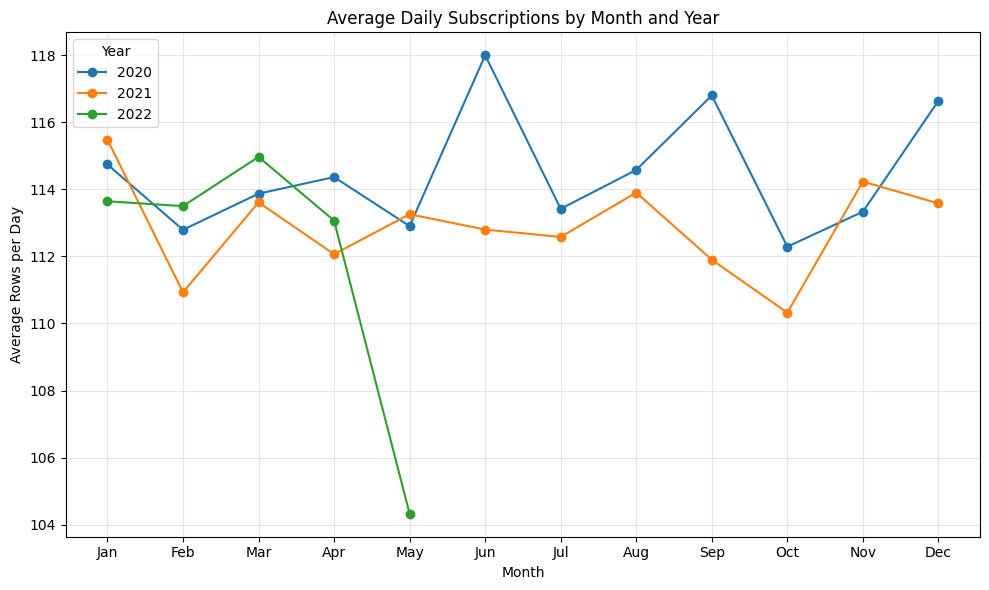

In [12]:
pivot_df = monthly_counts.pivot(
    index="month",
    columns="year",
    values="per_day"
)

pivot_df = pivot_df.reindex(range(1, 13))

pivot_df.plot(
    kind="line",
    marker="o",
    figsize=(10, 6)
)

plt.xticks(
    ticks=range(1, 13),
    labels=[
        "Jan", "Feb", "Mar", "Apr", "May", "Jun",
        "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
    ]
)
plt.xlabel("Month")
plt.ylabel("Average Rows per Day")
plt.title("Average Daily Subscriptions by Month and Year")
plt.grid(True, alpha=0.3)
plt.legend(title="Year")
plt.tight_layout()
plt.show()

# Insight

5. Seems like our assumption on Feb is correct, the Daily avg is not that behind when compared against other months 

Checking the May 2022 data.

In [13]:
may_2022 = df[
    (df["Subscription Date"].dt.year == 2022) &
    (df["Subscription Date"].dt.month == 5)
]

In [14]:
all_dates = pd.date_range(
    start="2022-05-01",
    end="2022-05-31",
    freq="D"
)

daily_counts = (
    may_2022.groupby(may_2022["Subscription Date"].dt.normalize())
    .size()
    .reindex(all_dates, fill_value=0)
)

print(daily_counts)

2022-05-01    113
2022-05-02    137
2022-05-03    112
2022-05-04    116
2022-05-05    111
2022-05-06    108
2022-05-07    107
2022-05-08    117
2022-05-09    104
2022-05-10    103
2022-05-11    101
2022-05-12     97
2022-05-13    115
2022-05-14    103
2022-05-15    110
2022-05-16     99
2022-05-17    102
2022-05-18    100
2022-05-19    105
2022-05-20    108
2022-05-21    111
2022-05-22    132
2022-05-23    113
2022-05-24    121
2022-05-25    118
2022-05-26    121
2022-05-27    123
2022-05-28    114
2022-05-29    113
2022-05-30      0
2022-05-31      0
Freq: D, dtype: int64


In [15]:
filled_dates = pd.date_range(
    start="2022-05-01",
    end="2022-05-29",
    freq="D"
)

filled_daily_counts = (
    may_2022.groupby(may_2022["Subscription Date"].dt.normalize())
    .size()
    .reindex(filled_dates, fill_value=0)
)
daily_avg = filled_daily_counts.mean()

print(f"Daily avg May 2022: {daily_avg:.2f}")

Daily avg May 2022: 111.52


# Insight

6. Seems like the data for May is almost complete, the only missing day is 30 and 31 May. Assuming if the 2 missing days have the average number of subscription on May 2022, it will sit in the normal range of complete months.

Checking if there is seasonality in the data

In [16]:
# we will be only using the complete months for the best/worst comparison, excluding May 2022
complete = monthly_counts[~((monthly_counts["year"] == 2022) & (monthly_counts["month"] == 5))]
best = complete["per_day"].max()
worst = complete["per_day"].min()

gap_pct = (best - worst) / worst * 100


print(f"Best daily average: {best:.2f}")
print(f"Worst daily average: {worst:.2f}")
print(f"Best-to-worst gap: {gap_pct:.2f}%")

Best daily average: 118.00
Worst daily average: 110.32
Best-to-worst gap: 6.96%


## Insight

7. There is no clear sign of seasonality pattern in this data. After we adjust the number of days in each month, the February dips disappeared. The best-to-worst gap is only ~7% (110–118 per day), and no month stands out consistently.

## Summary

- Data Quality : Found some duplicates on emails which seems like dont belong to the customer first and last name. This also suggest that the dataset seems like a synthetic dataset.

- Customer : The dataset shows that every entry have different customer id, this suggest that this file is a new subscription only dataset. Resubscription is not logged in this file. 

- Trend : There is no clear sign of seasonality, February showed dip but it is because of lower number of days in that month. The best-to-worst performing month gap is only at 7%. 

- May 2022 Issue : This specific month seems have a lower data count due to it missing the last 2 day data (30 and 31 May), assuming it is the current date. If the data comes in and still in the average value of May 2022 day-to-day data, the month performance will still be in a tolerable range.